# Simulating Option Color under the BSM Framework

## Objective

This notebook studies how an option's Color behaves under the Black–Scholes–Merton (BSM) framework, and how it responds to changes in moneyness, time to maturity, volatility, the risk-free rate and the dividend yield. Unlike Charm, Color is the same for calls and puts at every dividend yield, so one curve covers both. It also connects Color to the Greeks it is built from: Gamma, Charm and Theta.

## What Color measures

Color (also called gamma decay or gamma bleed) is the rate at which an option's Gamma changes as time passes, with all other inputs held constant:

$$
\text{Color} = \frac{\partial \Gamma}{\partial t} = -\frac{\partial \Gamma}{\partial T}
$$

where $\Gamma = \frac{\partial^2 V}{\partial S^2} = \frac{\partial \Delta}{\partial S}$ is the option's Gamma, $t$ is calendar time, and $T$ is the time remaining to maturity in years.

Color is a **third-order Greek**: it differentiates the option value three times, twice with respect to the stock price and once with respect to time. The order of differentiation does not matter, so Color can be read in three equivalent ways:

$$
\text{Color} = \frac{\partial}{\partial t}\left(\frac{\partial^2 V}{\partial S^2}\right) = \frac{\partial}{\partial S}\left(\frac{\partial^2 V}{\partial S\,\partial t}\right) = \frac{\partial\, \text{Charm}}{\partial S} = \frac{\partial^2 \Theta}{\partial S^2}
$$

So Color is **how fast Gamma drifts as time passes**, **the slope of the Charm curve** from notebook 02, and **the curvature of the Theta curve** from notebook 01. This notebook shows the first two readings directly.

**Why it matters:** Gamma tells a Delta hedger how much the hedge has to change when the stock moves. Color tells them how much that sensitivity itself changes each day, even if the stock never moves. A position that looks safe today can carry several times more Gamma a few weeks later, purely from the passage of time.

**Sign convention:** Color is measured as calendar time passes, the same direction as Theta in notebook 01 and Charm in notebook 02. A positive Color means Gamma rises as time passes; a negative Color means it falls. Some sources define Color as $\partial \Gamma / \partial T$ instead, which flips the sign.

**Scaling:** the formula gives Color per year. All values and plots in this notebook report Color per calendar day, i.e. the change in Gamma over one day:

$$
\text{Color}_{\text{day}} = \frac{\text{Color}_{\text{year}}}{365}
$$

This matches the per-day scaling used for Theta and Charm. Like them, Color is an instantaneous rate: it describes how fast Gamma is changing right now, not a fixed amount it changes by every day until expiry.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# Color values are of order 1e-5 or smaller, so tables show 8 decimal places
pd.set_option("display.precision", 8)

## Color Formula under BSM

Under BSM with a continuous dividend yield $q$, Gamma is

$$
\Gamma_{\text{call}} = \Gamma_{\text{put}} = \Gamma = \frac{e^{-qT}N'(d_1)}{S\sigma\sqrt{T}}
$$

Differentiating Gamma with respect to calendar time gives Color (per year):

$$
\text{Color} = \frac{e^{-qT}N'(d_1)}{2ST\sigma\sqrt{T}}\left[2qT + 1 + d_1\,\frac{2(r-q)T - d_2\sigma\sqrt{T}}{\sigma\sqrt{T}}\right] = \frac{\Gamma}{2T}\left[2qT + 1 + d_1\,\frac{2(r-q)T - d_2\sigma\sqrt{T}}{\sigma\sqrt{T}}\right]
$$

where

$$
d_1 = \frac{\ln(S/K) + \left(r - q + \frac{\sigma^2}{2}\right)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}
$$

and

- $S$: current price of the underlying
- $K$: strike price
- $T$: time to maturity, in years
- $r$: continuously compounded risk-free rate
- $q$: continuous dividend yield
- $\sigma$: volatility of the underlying
- $N(x)$: standard normal cumulative distribution function
- $N'(x) = \frac{1}{\sqrt{2\pi}}e^{-x^2/2}$: standard normal probability density function

### The four parts of Color

Multiplying out the bracket gives four parts, each with its own meaning:

$$
\text{Color} = \underbrace{\frac{\Gamma}{2T}}_{(1)\ \text{concentration}}\ \underbrace{-\ \Gamma\,\frac{d_1 d_2}{2T}}_{(2)\ \text{convergence}}\ \underbrace{+\ \Gamma\,\frac{d_1(r-q)}{\sigma\sqrt{T}}}_{(3)\ \text{drift}}\ \underbrace{+\ q\,\Gamma}_{(4)\ \text{dividends}}
$$

All four parts are the same for calls and puts.

1. **Concentration**, $\frac{\Gamma}{2T}$: Gamma has $\sigma\sqrt{T}$ in its denominator. As time passes the range of prices the stock can realistically reach by expiry gets narrower, so the same probability is packed into a smaller range and Gamma rises. This part is always positive, largest where Gamma itself is largest, and grows rapidly as $T \to 0$ because of the $\frac{1}{T}$ factor.

2. **Convergence**, $-\Gamma\frac{d_1 d_2}{2T}$: at expiry Gamma is zero everywhere except exactly at the strike. As time passes, options away from the strike lose their Gamma as their Delta settles at 0 or 1. This part is negative wherever $d_1$ and $d_2$ have the same sign, i.e. everywhere except a narrow strip between the points $d_1 = 0$ and $d_2 = 0$. It is the same convergence effect as in Charm, seen one derivative further on. Like the concentration part, it carries a $\frac{1}{T}$ factor.

3. **Drift**, $+\Gamma\frac{d_1(r-q)}{\sigma\sqrt{T}}$: BSM prices options as if the stock grows on average at the rate $r - q$. That growth shifts the Gamma curve to the left of the strike (its peak sits at $S/K = e^{-(r - q + 3\sigma^2/2)T}$). As time passes less growth remains, so the peak slides back toward the strike, adding Gamma on the right of $d_1 = 0$ and removing it on the left. With $r > q$ the drift part is negative where $d_1 < 0$ and positive where $d_1 > 0$; it is zero when $r = q$.

4. **Dividends**, $+q\Gamma$: Gamma is scaled by $e^{-qT}$. As time passes fewer dividends remain, $e^{-qT}$ rises toward 1, and Gamma rises with it. This part is zero when $q = 0$.

**Calls vs puts:** call Delta minus put Delta always equals $e^{-qT}$, which does not depend on $S$. Differentiating with respect to $S$ removes it, so call and put Gamma are identical, and therefore so is their Color, **for any dividend yield**. This is the main structural difference from Charm, where $q > 0$ separated calls and puts by $qe^{-qT}$ per year. That gap is the same at every stock price, so its slope, which is what Color measures, is zero.

In [2]:
DAYS_PER_YEAR = 365


def d1_d2(S, K, T, r, q, sigma):
    d1 = (np.log(S / K) + (r - q + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return d1, d2


def delta(S, K, T, r, q, sigma, option):
    d1, _ = d1_d2(S, K, T, r, q, sigma)
    if option == "call":
        return np.exp(-q * T) * norm.cdf(d1)
    if option == "put":
        return -np.exp(-q * T) * norm.cdf(-d1)
    raise ValueError("option must be 'call' or 'put'")


def gamma(S, K, T, r, q, sigma):
    d1, _ = d1_d2(S, K, T, r, q, sigma)
    return np.exp(-q * T) * norm.pdf(d1) / (S * sigma * np.sqrt(T))


def gamma_from_delta(S, K, T, r, q, sigma, option, h=0.01):
    # Gamma estimated from one option's own Delta (central difference), used to check call = put
    return (delta(S + h, K, T, r, q, sigma, option) - delta(S - h, K, T, r, q, sigma, option)) / (2 * h)


def charm(S, K, T, r, q, sigma, option):
    d1, d2 = d1_d2(S, K, T, r, q, sigma)
    shared = -np.exp(-q * T) * norm.pdf(d1) * (2 * (r - q) * T - d2 * sigma * np.sqrt(T)) / (2 * T * sigma * np.sqrt(T))
    if option == "call":
        return (q * np.exp(-q * T) * norm.cdf(d1) + shared) / DAYS_PER_YEAR
    if option == "put":
        return (-q * np.exp(-q * T) * norm.cdf(-d1) + shared) / DAYS_PER_YEAR
    raise ValueError("option must be 'call' or 'put'")


def color_parts(S, K, T, r, q, sigma):
    d1, d2 = d1_d2(S, K, T, r, q, sigma)
    g = gamma(S, K, T, r, q, sigma)
    concentration = g / (2 * T)
    convergence = -g * d1 * d2 / (2 * T)
    drift = g * d1 * (r - q) / (sigma * np.sqrt(T))
    dividend = q * g
    return (concentration / DAYS_PER_YEAR, convergence / DAYS_PER_YEAR,
            drift / DAYS_PER_YEAR, dividend / DAYS_PER_YEAR)


def color(S, K, T, r, q, sigma):
    return sum(color_parts(S, K, T, r, q, sigma))


def sign_changes(x, y):
    # x-values at which y changes sign (first grid point after each change)
    return x[1:][np.diff(np.sign(y)) != 0]

## Base Case and Parameter Ranges

Unless a plot states otherwise, every calculation uses the base case below. Each plot varies one or two parameters at a time and holds the rest at their base values. These are the same choices as in notebooks 01 and 02, so the three notebooks can be compared directly.

| Parameter | Base case | Values used when varied |
|---|---|---|
| Stock price $S$ | 100 | 50 to 150, in steps of 0.1 |
| Strike price $K$ | 100 | fixed |
| Time to maturity $T$ | 1 year | 1 week, 1 month, 3 months, 1 year; and a continuous range from 1 day to 2 years |
| Volatility $\sigma$ | 20% | 10%, 20%, 40% |
| Risk-free rate $r$ | 5% | 0%, 5%, 10% |
| Dividend yield $q$ | 0% | 0%, 5%, 10% |

**Moneyness** is measured as $S/K$, from 0.5 to 1.5:

- $S/K < 1$: the call is out of the money (OTM) and the put is in the money (ITM).
- $S/K = 1$: both are at the money (ATM).
- $S/K > 1$: the call is ITM and the put is OTM.

When comparing ITM, ATM and OTM options directly, we use $S/K = 0.9$, $1.0$ and $1.1$.

**Notes on these choices:**

- $K$ is fixed at 100. Unlike Delta and Charm, Gamma and Color are **not** functions of $S/K$ alone: Gamma is measured per unit of stock price, so for a fixed $S/K$ it scales as $\frac{1}{K}$. Every Gamma and Color value below is for $K = 100$; for another strike, multiply by $\frac{100}{K}$. The shapes of the curves and the points where Color changes sign do not depend on $K$.
- $S$ moves in steps of 0.1 because, close to expiry, Color is concentrated in a very narrow band around ATM. A coarser step would miss its peaks.
- Maturities are converted to years using calendar days: 1 week = $7/365$, 1 month = $30/365$, 3 months = $90/365$.
- The shortest maturity is 1 day, because the formula divides by $T$ and cannot be evaluated at $T = 0$.
- The values of $r$ and $q$ are set wider than typical market levels so that their effects are clearly visible.
- **Calls and puts:** call and put Color are identical at every dividend yield (checked in the base-case table and the dividend-yield plot below). Every plot therefore shows a single curve that applies to both.

In [3]:
K = 100
T_BASE = 1.0
SIGMA_BASE = 0.20
R_BASE = 0.05
Q_BASE = 0.0

S_GRID = np.linspace(50, 150, 1001)
moneyness = S_GRID / K
DAYS = np.arange(1, 731)
T_GRID = DAYS / DAYS_PER_YEAR

MATURITIES = {"1 week": 7 / 365, "1 month": 30 / 365, "3 months": 90 / 365, "1 year": 1.0}
MONEYNESS_LEVELS = [0.9, 1.0, 1.1]
SIGMAS = [0.10, 0.20, 0.40]
RATES = [0.00, 0.05, 0.10]
DIV_YIELDS = [0.00, 0.05, 0.10]

## Base-Case Color Values

Color predicts how much Gamma will change over one day. As a check, the table compares it with the actual change: Gamma is computed today ($T = 1$ year) and again one calendar day later ($T = 1 - \frac{1}{365}$), with the stock price and all other inputs unchanged.

To show that calls and puts really share the same Gamma, Gamma here is not taken from the closed-form formula: it is estimated separately from each option's own Delta, as the change in Delta for a 0.01 move in $S$ either side.

Parameters: $K = 100$, $\sigma = 20\%$, $r = 5\%$, $q = 0$, at $S/K = 0.9$, $1.0$ and $1.1$, for calls and puts.

In [4]:
one_day = 1 / DAYS_PER_YEAR
rows = []

for option in ["call", "put"]:
    for m in MONEYNESS_LEVELS:
        gamma_today = gamma_from_delta(m * K, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, option)
        gamma_tomorrow = gamma_from_delta(m * K, K, T_BASE - one_day, R_BASE, Q_BASE, SIGMA_BASE, option)
        rows.append({"option": option, "S/K": m,
                     "gamma today": gamma_today, "gamma tomorrow": gamma_tomorrow,
                     "actual change": gamma_tomorrow - gamma_today,
                     "color (per day)": color(m * K, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE)})

pd.DataFrame(rows).round(8)

,option,S/K,gamma today,gamma tomorrow,actual change,color (per day)
0,call,0.9,0.02181975,0.02184504,0.00002529,0.00002526
1,call,1.0,0.01876202,0.01879092,0.00002891,0.00002885
2,call,1.1,0.01288651,0.01290234,0.00001583,0.00001581
3,put,0.9,0.02181975,0.02184504,0.00002529,0.00002526
4,put,1.0,0.01876202,0.01879092,0.00002891,0.00002885
5,put,1.1,0.01288651,0.01290234,0.00001583,0.00001581


### Observations

1. **Color predicts the daily change in Gamma:** in every row, the actual one-day change in Gamma matches Color to three significant figures (for example +0.00002529 against +0.00002526 at $S/K = 0.9$). The small remaining gap, about $3 \times 10^{-8}$, is there because Color itself changes slightly over the day; it is a fraction of a percent of the value. This confirms both the formula and the per-day scaling.

2. **The changes are small with a year left, but they add up:** the ATM option's Gamma rises by about 0.0000289 per day, so over a month it grows by roughly 30 × 0.0000289 ≈ 0.00087, about 5% of its current Gamma (0.018762), even if the stock price never moves. Each re-hedge after a stock move will be about 5% larger than it is today.

3. **All three options gain Gamma:** with a year left, $S/K = 0.9$, $1.0$ and $1.1$ all lie inside the range where Gamma is building up (+0.00002526, +0.00002885 and +0.00001581). The ATM option gains the most because it sits closest to the peak of the Color curve; $S/K = 1.1$ gains the least, about 55% of the ATM figure. The plots below show where Color turns negative.

4. **Calls and puts match exactly:** the put rows, computed only from put Delta, are identical to the call rows. Put Delta is call Delta minus 1 here, so both change by the same amount for any move in $S$, and their Gamma, and the daily change in their Gamma, are the same.

## Gamma vs Moneyness at Different Maturities

Before plotting Color itself, this plot shows what Color describes: how the whole Gamma curve changes shape as expiry approaches.

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for four maturities: 1 week, 1 month, 3 months and 1 year
- **Held constant:** $K = 100$, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** Gamma, which is the same for calls and puts. The table below gives Gamma at $S/K = 0.9$, $1.0$ and $1.1$ for each maturity, and the moneyness at which Gamma peaks.

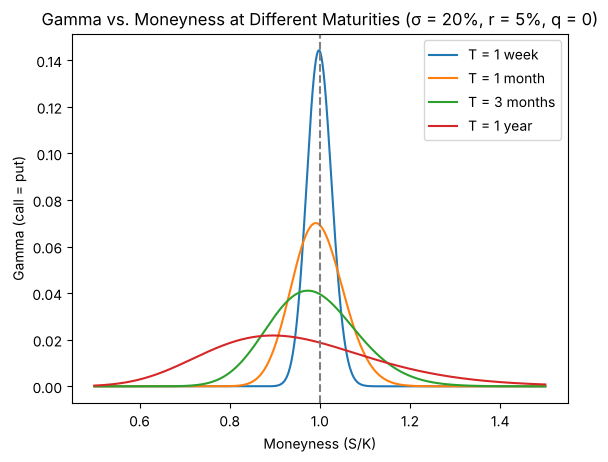

,maturity,gamma at S/K = 0.9,gamma at S/K = 1.0,gamma at S/K = 1.1,peak at S/K
0,1 week,0.0001,0.1439,0.0003,0.998
1,1 month,0.0171,0.0692,0.0134,0.991
2,3 months,0.0301,0.0396,0.0192,0.973
3,1 year,0.0218,0.0188,0.0129,0.896


In [5]:
for label, T in MATURITIES.items():
    plt.plot(moneyness, gamma(S_GRID, K, T, R_BASE, Q_BASE, SIGMA_BASE), label=f"T = {label}")

plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("Moneyness (S/K)")
plt.ylabel("Gamma (call = put)")
plt.title("Gamma vs. Moneyness at Different Maturities (σ = 20%, r = 5%, q = 0)")
plt.legend()
plt.show()

rows = []
for label, T in MATURITIES.items():
    row = {"maturity": label}
    for m in MONEYNESS_LEVELS:
        row[f"gamma at S/K = {m}"] = gamma(m * K, K, T, R_BASE, Q_BASE, SIGMA_BASE)
    row["peak at S/K"] = moneyness[np.argmax(gamma(S_GRID, K, T, R_BASE, Q_BASE, SIGMA_BASE))]
    rows.append(row)

pd.DataFrame(rows).round(4)

### Observations

1. **The Gamma curve sharpens into a spike as expiry approaches:** with 1 year left, Gamma is a low, wide hump (0.0188 ATM). With 1 week left, it is a tall, narrow spike (0.1439 ATM, almost eight times higher) and is close to zero a few percent away from the strike. At expiry it becomes infinitely tall at the strike and zero everywhere else, because Delta becomes a step there.

2. **Options near the strike keep gaining Gamma; options away from it gain and then lose it:** ATM Gamma rises at every step (0.0188, 0.0396, 0.0692, 0.1439). Away from the strike, Gamma first rises and then collapses: at $S/K = 0.9$ it goes from 0.0218 at 1 year to 0.0301 at 3 months, then 0.0171 and 0.0001; at $S/K = 1.1$ from 0.0129 to 0.0192, then 0.0134 and 0.0003. Color measures how fast each of these changes happens, and the rise-then-collapse paths show that its sign can flip as maturity shortens.

3. **The peak moves toward the strike:** Gamma peaks at $S/K \approx 0.896$ with 1 year left, 0.973 at 3 months, 0.991 at 1 month and 0.998 at 1 week. The peak sits at $S/K = e^{-(r - q + 3\sigma^2/2)T}$, which is $e^{-0.11} \approx 0.896$ in the base case and approaches 1 as $T$ shrinks. This shift is the drift part of Color at work.

4. **One curve for calls and puts:** call and put Gamma are identical, so there is no separate put panel. Compare this with the Delta plot in notebook 02, where the put curves were the call curves shifted down by 1. Gamma is the slope of those curves, and a shift does not change a slope.

## Color vs Moneyness (Base Case)

- **Varying:** stock price $S$ from 50 to 150, so moneyness $S/K$ runs from 0.5 to 1.5
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** Color from the formula (solid), which applies to calls and puts, and the actual one-day change in Gamma at every stock price (dashed) as a check across the whole range

The dashed vertical line at $S/K = 1$ marks ATM. Below the horizontal line at 0, Gamma falls as time passes; above it, Gamma rises.

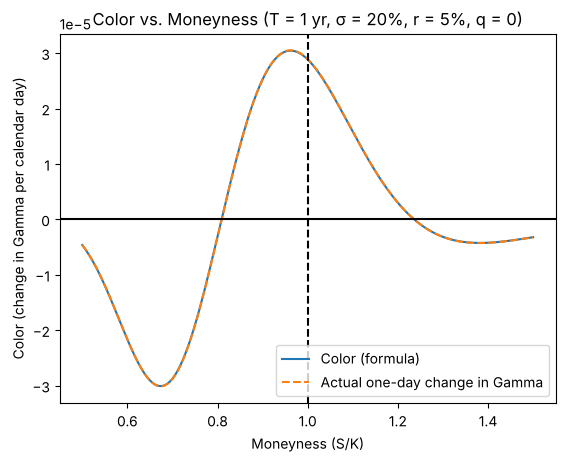

Most negative: S/K = 0.674, color = -0.00003009
Most positive: S/K = 0.962, color = 0.00003044
ATM color = 0.00002885
Color changes sign at S/K = 0.810, 1.237
Largest gap between color and the actual one-day change: 7.49e-08


In [6]:
base_color = color(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE)
actual_change = (gamma(S_GRID, K, T_BASE - one_day, R_BASE, Q_BASE, SIGMA_BASE)
                 - gamma(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE))

plt.plot(moneyness, base_color, label="Color (formula)")
plt.plot(moneyness, actual_change, linestyle="--", label="Actual one-day change in Gamma")
plt.axhline(0, color="black")
plt.axvline(1, color="black", linestyle="--")
plt.xlabel("Moneyness (S/K)")
plt.ylabel("Color (change in Gamma per calendar day)")
plt.title("Color vs. Moneyness (T = 1 yr, σ = 20%, r = 5%, q = 0)")
plt.legend()
plt.show()

print(f"Most negative: S/K = {moneyness[np.argmin(base_color)]:.3f}, color = {base_color.min():.8f}")
print(f"Most positive: S/K = {moneyness[np.argmax(base_color)]:.3f}, color = {base_color.max():.8f}")
print(f"ATM color = {color(K, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE):.8f}")
print(f"Color changes sign at S/K = {', '.join(f'{x:.3f}' for x in sign_changes(moneyness, base_color))}")
print(f"Largest gap between color and the actual one-day change: {np.abs(base_color - actual_change).max():.2e}")

### Observations

1. **Color is positive in a band around the strike and negative outside it:** Gamma rises as time passes between $S/K \approx 0.810$ and $1.237$, and falls outside that range. This is the Gamma curve from the previous plot getting taller and narrower, seen one day at a time.

2. **The two sides are similar in size, unlike Charm:** Color is most positive at $S/K \approx 0.962$ (+0.00003044 per day), just below the strike, and most negative at $S/K \approx 0.674$ (−0.00003009), a fairly deep OTM call. Charm's negative side was four times its positive side; for Color the peak and trough are almost equal. ATM Color is +0.00002885.

3. **The OTM side decays much more than the ITM side:** below the band, Color dips to −0.00003009; above it, it never goes below about −0.0000043 (see the dividend-yield section). The Gamma curve sits to the left of the strike when $r > q$, so there is more Gamma on the OTM side to lose.

4. **Far from the strike, Color fades toward zero:** deep OTM and deep ITM, Gamma is already close to zero, so there is little left to change.

5. **The formula matches the one-day change everywhere:** the largest gap across the grid is $7.5 \times 10^{-8}$, against Color values of up to $3 \times 10^{-5}$.

## Components of Color vs Moneyness (Base Case)

- **Varying:** stock price $S$ from 50 to 150, so moneyness $S/K$ runs from 0.5 to 1.5
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** Color split into the concentration, convergence and drift parts, with the total Color for comparison

The dividend part is zero everywhere because $q = 0$, so it is not plotted. All parts apply equally to calls and puts.

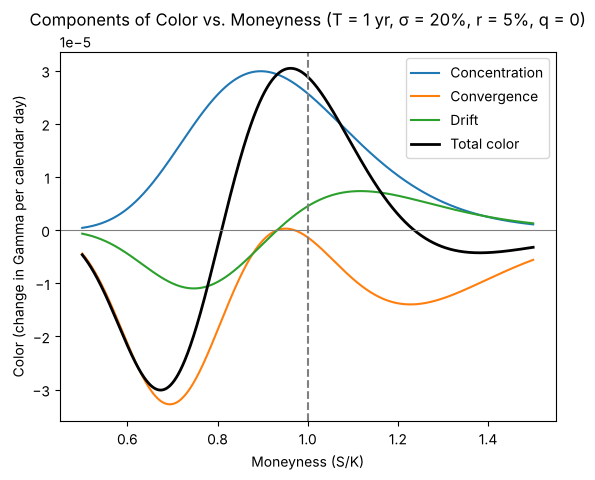

Concentration part is most positive at S/K = 0.896 (0.00002990), ATM 0.00002570
Convergence part is positive between S/K = 0.933, 0.971; most negative at S/K = 0.694 (-0.00003277), most positive 0.00000029
Drift part changes sign at S/K = 0.933; most negative at S/K = 0.748 (-0.00001097), most positive at S/K = 1.117 (0.00000735)


In [7]:
concentration, convergence, drift, dividend = color_parts(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE)

plt.plot(moneyness, concentration, label="Concentration")
plt.plot(moneyness, convergence, label="Convergence")
plt.plot(moneyness, drift, label="Drift")
plt.plot(moneyness, concentration + convergence + drift + dividend, color="black", linewidth=2, label="Total color")
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("Moneyness (S/K)")
plt.ylabel("Color (change in Gamma per calendar day)")
plt.title("Components of Color vs. Moneyness (T = 1 yr, σ = 20%, r = 5%, q = 0)")
plt.legend()
plt.show()

print(f"Concentration part is most positive at S/K = {moneyness[np.argmax(concentration)]:.3f} ({concentration.max():.8f}), "
      f"ATM {concentration[500]:.8f}")
print(f"Convergence part is positive between S/K = {', '.join(f'{x:.3f}' for x in sign_changes(moneyness, convergence))}; "
      f"most negative at S/K = {moneyness[np.argmin(convergence)]:.3f} ({convergence.min():.8f}), "
      f"most positive {convergence.max():.8f}")
print(f"Drift part changes sign at S/K = {', '.join(f'{x:.3f}' for x in sign_changes(moneyness, drift))}; "
      f"most negative at S/K = {moneyness[np.argmin(drift)]:.3f} ({drift.min():.8f}), "
      f"most positive at S/K = {moneyness[np.argmax(drift)]:.3f} ({drift.max():.8f})")

### Observations

1. **The concentration part is positive everywhere:** it follows the shape of Gamma itself and peaks where Gamma peaks, at $S/K \approx 0.896$ (+0.00002990). Near the money it supplies almost all of Color: +0.00002570 of the ATM total of +0.00002885.

2. **The convergence part is what makes the wings negative:** it is negative almost everywhere and is deepest at $S/K \approx 0.694$ (−0.00003277), which is close to where total Color is deepest (0.674). It is only positive in the strip between $S/K \approx 0.933$ ($d_1 = 0$) and $0.971$ ($d_2 = 0$), and even there only reaches +0.00000029. Outside that strip, the option is clearly heading toward finishing in or out of the money, so its Delta is settling and its Gamma is draining away. The 0.971 point is the same 50-50 point where Charm's convergence part changed sign in notebook 02.

3. **The drift part tilts the curve:** it changes sign at $S/K \approx 0.933$, where $d_1 = 0$. Below that it is negative, reaching −0.00001097 at $S/K \approx 0.748$; above it is positive, up to +0.00000735 at $S/K \approx 1.117$. As the expected growth over the remaining time shrinks, the Gamma curve slides right, back toward the strike: Gamma is removed on the OTM side and added nearer the money.

4. **Adding the parts:** the concentration part lifts the middle, the convergence part pulls down the wings, and the drift part deepens the OTM wing while lifting the area just above the strike. Together they put the peak at 0.962 and the sign changes at 0.810 and 1.237.

## Color as the Slope of Charm

Color can also be read as $\frac{\partial\, \text{Charm}}{\partial S}$: the slope of the Charm curve from notebook 02. This plot checks that numerically. The slope of the call Charm curve is estimated with `np.gradient`, which divides the change in Charm between neighbouring grid points by the change in $S$. It is then compared with the Color formula.

Charm per day divided by a change in stock price is a change in Gamma per day, so the two are in the same units.

- **Varying:** stock price $S$ from 50 to 150, so moneyness $S/K$ runs from 0.5 to 1.5
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** call Charm (top), and Color with the slope of the Charm curve (bottom). The red dotted lines mark where Charm is most negative and most positive.

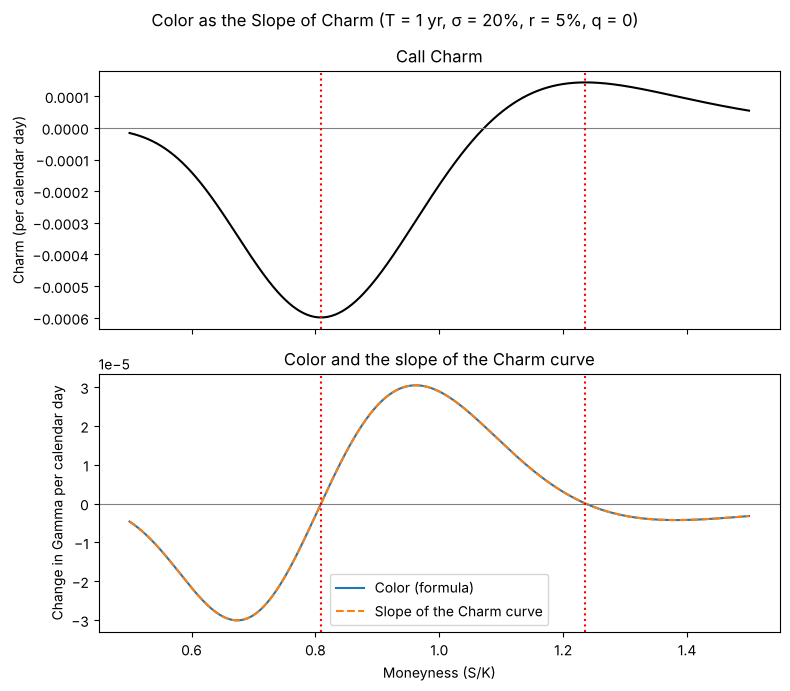

Charm is most negative at S/K = 0.809 and most positive at S/K = 1.236
Color changes sign at S/K = 0.810, 1.237
Largest gap between Color and the Charm slope: 5.32e-08


In [8]:
charm_call = charm(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, "call")
color_base = color(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE)
charm_slope = np.gradient(charm_call, S_GRID)
charm_min = moneyness[np.argmin(charm_call)]
charm_max = moneyness[np.argmax(charm_call)]

fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

ax_top.plot(moneyness, charm_call, color="black")
ax_top.axhline(0, color="gray", linewidth=0.8)
ax_top.set_ylabel("Charm (per calendar day)")
ax_top.set_title("Call Charm")

ax_bottom.plot(moneyness, color_base, label="Color (formula)")
ax_bottom.plot(moneyness, charm_slope, linestyle="--", label="Slope of the Charm curve")
ax_bottom.axhline(0, color="gray", linewidth=0.8)
ax_bottom.set_ylabel("Change in Gamma per calendar day")
ax_bottom.set_xlabel("Moneyness (S/K)")
ax_bottom.set_title("Color and the slope of the Charm curve")
ax_bottom.legend()

for ax in (ax_top, ax_bottom):
    ax.axvline(charm_min, color="red", linestyle=":")
    ax.axvline(charm_max, color="red", linestyle=":")

fig.suptitle("Color as the Slope of Charm (T = 1 yr, σ = 20%, r = 5%, q = 0)")
plt.tight_layout()
plt.show()

print(f"Charm is most negative at S/K = {charm_min:.3f} and most positive at S/K = {charm_max:.3f}")
print(f"Color changes sign at S/K = {', '.join(f'{x:.3f}' for x in sign_changes(moneyness, color_base))}")
print(f"Largest gap between Color and the Charm slope: {np.abs(color_base - charm_slope).max():.2e}")

### Observations

1. **The two curves match:** Color from the formula and the slope of the Charm curve lie on top of each other. The largest gap, about $5 \times 10^{-8}$, comes from the cruder slope estimate `np.gradient` uses at the first and last grid points, and is tiny compared with Color values of order $10^{-5}$.

2. **Color is zero exactly where Charm is at its extremes:** Charm is most negative at $S/K \approx 0.809$ and most positive at $1.236$; Color changes sign at $0.810$ and $1.237$, the same points up to the grid spacing. At the bottom and the top of the Charm curve its slope is zero, so Color is zero. Between them Charm rises with $S$ (positive Color); outside them it falls toward zero (negative Color).

3. **Two views of the same number:** Charm is how much Delta changes per day; Color is how that daily change varies with the stock price, which is the same as how Gamma changes per day. So the shape of the Charm curves in notebook 02 tells us the sign of Color: wherever a Charm curve rises as $S$ rises, Color is positive, and wherever it falls, Color is negative. Because call and put Charm differ only by a constant, put Charm has the same slope and the same Color at any dividend yield.

4. **The chain back to Theta:** Charm was the slope of Theta in notebook 02, so Color is the curvature of Theta, $\frac{\partial^2 \Theta}{\partial S^2}$. Color is zero at the inflection points of the Theta curve, where it switches from bending one way to bending the other.

## Color vs Moneyness at Different Maturities

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for four maturities: 1 week, 1 month, 3 months and 1 year
- **Held constant:** $K = 100$, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** a single curve per maturity, which applies to calls and puts

Color's size changes by a factor of about 340 between 1 year and 1 week, so each maturity gets its own panel with its own y-axis scale. The printed lines give the exact values for comparing across panels.

T = 1 week: most negative -0.00522966 at S/K = 0.952, most positive 0.01030871 at S/K = 0.999, positive between S/K = 0.973 and 1.029, ATM 0.01030050
T = 1 month: most negative -0.00067630 at S/K = 0.902, most positive 0.00117028 at S/K = 0.997, positive between S/K = 0.945 and 1.060, ATM 0.00116541
T = 3 months: most negative -0.00015747 at S/K = 0.833, most positive 0.00022934 at S/K = 0.991, positive between S/K = 0.905 and 1.107, ATM 0.00022646
T = 1 year: most negative -0.00003009 at S/K = 0.674, most positive 0.00003044 at S/K = 0.962, positive between S/K = 0.810 and 1.237, ATM 0.00002885


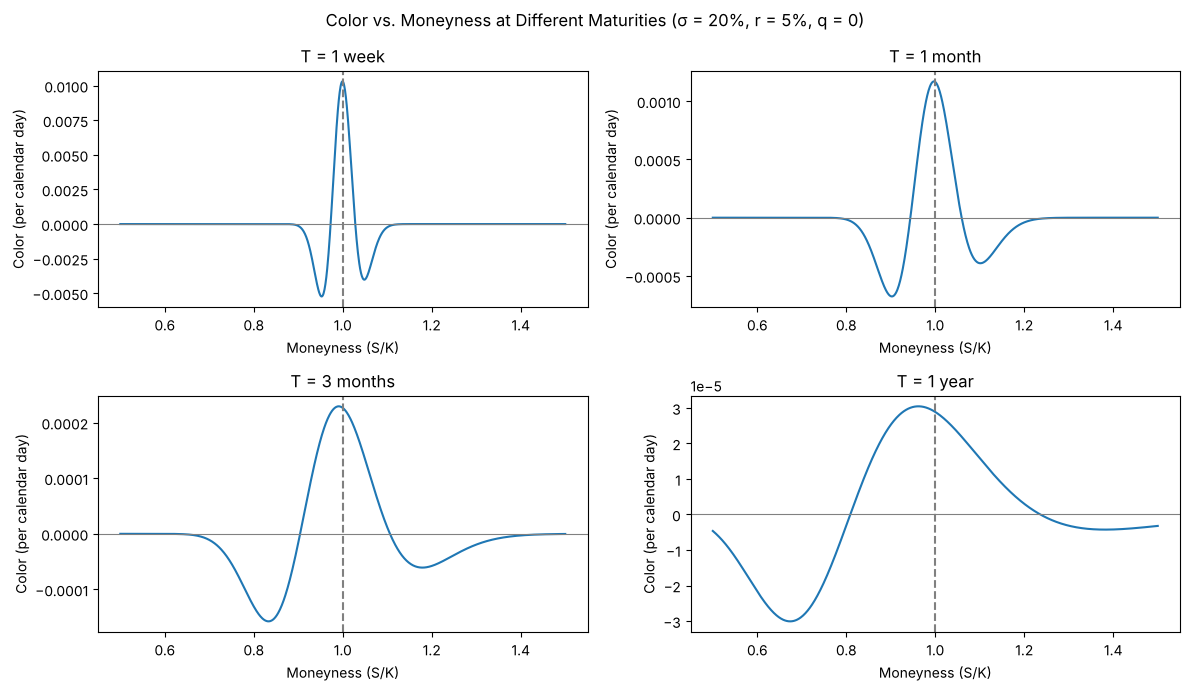

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, (label, T) in zip(axes.flat, MATURITIES.items()):
    c = color(S_GRID, K, T, R_BASE, Q_BASE, SIGMA_BASE)
    ax.plot(moneyness, c)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(1, color="gray", linestyle="--")
    ax.set_title(f"T = {label}")
    ax.set_xlabel("Moneyness (S/K)")
    ax.set_ylabel("Color (per calendar day)")
    print(f"T = {label}: most negative {c.min():.8f} at S/K = {moneyness[np.argmin(c)]:.3f}, "
          f"most positive {c.max():.8f} at S/K = {moneyness[np.argmax(c)]:.3f}, "
          f"positive between S/K = {' and '.join(f'{x:.3f}' for x in sign_changes(moneyness, c))}, "
          f"ATM {color(K, K, T, R_BASE, Q_BASE, SIGMA_BASE):.8f}")

fig.suptitle("Color vs. Moneyness at Different Maturities (σ = 20%, r = 5%, q = 0)")
plt.tight_layout()
plt.show()

### Observations

1. **Color grows very sharply as expiry approaches:** the most positive Color goes from +0.00003044 per day at 1 year to +0.00022934 at 3 months, +0.00117028 at 1 month and +0.01030871 at 1 week, about 340 times larger. The most negative goes from −0.00003009 to −0.00522966. With a week left, an ATM option's Gamma (0.1439) grows by about 7% of its own value in a single day. Color grows faster than Charm did (about 30 times over the same range) because Gamma itself grows like $\frac{1}{\sqrt{T}}$ at the money, and both the concentration and convergence parts multiply it by $\frac{1}{T}$.

2. **The positive band narrows around the strike:** Color is positive between $S/K \approx 0.810$ and $1.237$ at 1 year, 0.905 and 1.107 at 3 months, 0.945 and 1.060 at 1 month, and only 0.973 and 1.029 at 1 week. With a week left, only options within about 3% of the strike are still gaining Gamma; everything else is losing it.

3. **The positive side now dominates:** at 1 year the peak and the trough were about the same size. At 1 week the peak (+0.0103) is about twice the trough (−0.0052). The concentration part grows fastest at the money, while the drift part, which grows only like $\frac{1}{\sqrt{T}}$, matters less and less.

4. **The peak moves toward ATM:** from $S/K \approx 0.962$ at 1 year to 0.991, 0.997 and 0.999 at 1 week, following the Gamma peak. The sign-change points match, to within the grid spacing, the extremes of Charm for the same maturities in notebook 02 (for example 0.973 and 1.028 at 1 week), as expected since Color is the slope of Charm.

## Color vs Time to Maturity

- **Varying:** time to maturity, from 1 day to 2 years in steps of one calendar day
- **Held constant:** $K = 100$, $\sigma = 20\%$, $r = 5\%$, $q = 0$, at three moneyness levels: $S/K = 0.9$, $1.0$ and $1.1$
- **Shows:** a single curve per moneyness level, which applies to calls and puts; for puts, $S/K = 0.9$ is ITM and $1.1$ is OTM. ATM Color near expiry is over 200 times larger than anything the other two reach, so the right panel repeats the plot without it.

The x-axis uses a log scale, so the last few weeks before expiry are not squeezed into a sliver at the left edge. Moving left along the axis means time passing, i.e. getting closer to expiry. The table gives Color at five checkpoints, the maturity at which Color is largest in size, and the maturity at which it changes sign, if it does.

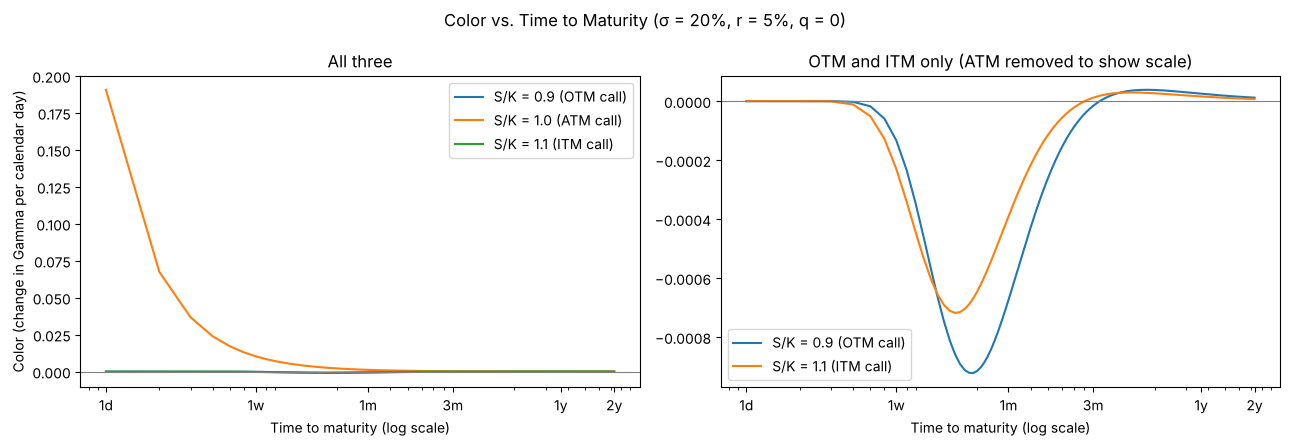

,S/K,type,1 day,1 week,1 month,1 year,2 years,largest at (days),changes sign at (days)
0,0.9,OTM,-0.00000000,-0.00013326,-0.00067431,0.00002526,0.00001179,19,99
1,1.0,ATM,0.19057651,0.01030050,0.00116541,0.00002885,0.00001064,1,never
2,1.1,ITM,-0.00000000,-0.00022994,-0.00039092,0.00001581,0.00000703,15,81


In [10]:
labels = {0.9: "OTM", 1.0: "ATM", 1.1: "ITM"}
rows = []
fig, (ax_all, ax_zoom) = plt.subplots(1, 2, figsize=(13, 4.5))

for m in MONEYNESS_LEVELS:
    c = color(m * K, K, T_GRID, R_BASE, Q_BASE, SIGMA_BASE)
    ax_all.plot(DAYS, c, label=f"S/K = {m} ({labels[m]} call)")
    if m != 1.0:
        ax_zoom.plot(DAYS, c, label=f"S/K = {m} ({labels[m]} call)")
    # c[i] is Color with i + 1 days to maturity
    rows.append({"S/K": m, "type": labels[m],
                 "1 day": c[0], "1 week": c[6], "1 month": c[29],
                 "1 year": c[364], "2 years": c[729],
                 "largest at (days)": np.argmax(np.abs(c)) + 1,
                 "changes sign at (days)": ", ".join(str(d) for d in sign_changes(DAYS, c)) or "never"})

for ax, title in [(ax_all, "All three"), (ax_zoom, "OTM and ITM only (ATM removed to show scale)")]:
    ax.set_xscale("log")
    ax.set_xticks([1, 7, 30, 90, 365, 730], ["1d", "1w", "1m", "3m", "1y", "2y"])
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xlabel("Time to maturity (log scale)")
    ax.set_title(title)
    ax.legend()

ax_all.set_ylabel("Color (change in Gamma per calendar day)")
fig.suptitle("Color vs. Time to Maturity (σ = 20%, r = 5%, q = 0)")
plt.tight_layout()
plt.show()

pd.DataFrame(rows).round(8)

### Observations

1. **ATM: Color grows without limit as expiry approaches:** +0.00001064 per day at 2 years, +0.00002885 at 1 year, +0.00116541 at 1 month, +0.01030050 at 1 week and +0.19057651 at 1 day, and it never changes sign. ATM Gamma grows like $\frac{1}{\sqrt{T}}$, so Color grows like $T^{-3/2}$: going from 7 days to 1 day multiplies it by about $7^{1.5} \approx 18.5$, which is what the table shows (0.1906 / 0.0103). This is the expiry-day Gamma risk option desks watch for. It parallels ATM Charm in notebook 02, which was also largest at 1 day and never changed sign, although Charm was negative and Color is positive.

2. **OTM call ($S/K = 0.9$): negative near expiry, positive further out:** for maturities shorter than 99 days, Gamma falls as time passes (−0.000133 at 1 week, −0.000674 at 1 month). It is strongest at about 19 days (about −0.00092 per day), as the option's chance of reaching the strike disappears. For maturities longer than 99 days, Color is positive (+0.00002526 at 1 year): there is still enough time that the narrowing of the distribution adds Gamma. This is the rise-then-collapse of Gamma at $S/K = 0.9$ seen in the Gamma table.

3. **ITM call ($S/K = 1.1$): the same pattern, slightly weaker and earlier:** Color is negative for maturities shorter than 81 days (−0.000230 at 1 week, −0.000391 at 1 month), strongest at about 15 days (about −0.00072), and positive beyond 81 days (+0.00001581 at 1 year). As with Charm, the OTM option reacts more strongly than the ITM one.

4. **Right before expiry, OTM and ITM Color is zero:** with 1 day left, both options' Gamma is already gone, so there is nothing left to decay. The same two speeds seen for Theta and Charm show up again: ATM Color is strongest at the shortest maturity, while away from the money it is strongest at intermediate maturities of two to three weeks.

## Color vs Moneyness at Different Volatilities

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for three volatilities: $\sigma = 10\%$, $20\%$ and $40\%$
- **Held constant:** $K = 100$, $T = 1$ year, $r = 5\%$, $q = 0$
- **Shows:** a single curve per volatility, which applies to calls and puts

σ = 10%: most negative -0.00006316 at S/K = 0.814, most positive 0.00006642 at S/K = 0.975, changes sign at S/K = 0.893, 1.121, ATM 0.00006119
σ = 20%: most negative -0.00003009 at S/K = 0.674, most positive 0.00003044 at S/K = 0.962, changes sign at S/K = 0.810, 1.237, ATM 0.00002885
σ = 40%: most negative -0.00001924 at S/K = 0.500, most positive 0.00001571 at S/K = 0.905, changes sign at S/K = 0.657, ATM 0.00001433


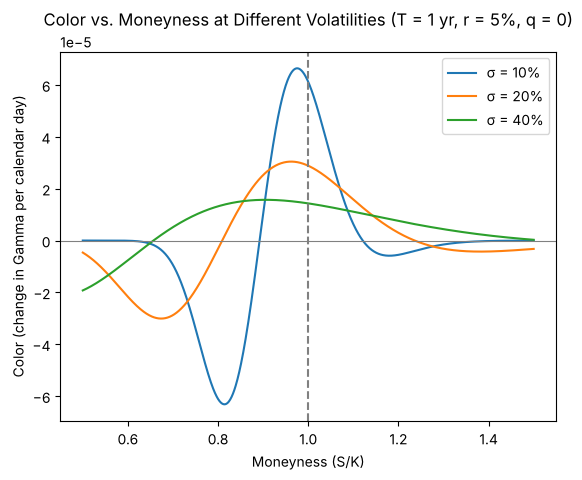

In [11]:
for sigma in SIGMAS:
    c = color(S_GRID, K, T_BASE, R_BASE, Q_BASE, sigma)
    plt.plot(moneyness, c, label=f"σ = {sigma:.0%}")
    print(f"σ = {sigma:.0%}: most negative {c.min():.8f} at S/K = {moneyness[np.argmin(c)]:.3f}, "
          f"most positive {c.max():.8f} at S/K = {moneyness[np.argmax(c)]:.3f}, "
          f"changes sign at S/K = {', '.join(f'{x:.3f}' for x in sign_changes(moneyness, c))}, "
          f"ATM {color(K, K, T_BASE, R_BASE, Q_BASE, sigma):.8f}")

plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("Moneyness (S/K)")
plt.ylabel("Color (change in Gamma per calendar day)")
plt.title("Color vs. Moneyness at Different Volatilities (T = 1 yr, r = 5%, q = 0)")
plt.legend()
plt.show()

### Observations

1. **Lower volatility gives a taller, narrower Color curve:** at $\sigma = 10\%$ the peak is +0.00006642 and the trough −0.00006316, about twice the 20% values, and Color is positive only between $S/K \approx 0.893$ and $1.121$. Gamma has $\sigma$ in its denominator, so low volatility gives a tall, narrow Gamma curve with a lot to gain or lose each day. Low volatility does to Color what a short maturity does, because both shrink $\sigma\sqrt{T}$.

2. **Higher volatility flattens and widens it:** at 40% the peak falls to +0.00001571 and ATM Color is +0.00001433, half the 20% value. Color is positive from $S/K \approx 0.657$ to beyond the right edge of the plot, and the most negative printed value (−0.00001924) sits at the left edge, $S/K = 0.5$, so the true trough lies further out of the money.

3. **The peak moves left as volatility rises:** from $S/K \approx 0.975$ at 10% to 0.962 at 20% and 0.905 at 40%. It moves in the same direction as the Gamma peak itself, $e^{-(r + 3\sigma^2/2)T}$, which sits at 0.937, 0.896 and 0.748 for the three volatilities: a wider distribution places more of the Gamma below the strike.

4. **The sign changes match Charm's extremes:** 0.893 and 1.121 at 10%, matching the Charm extremes at 0.892 and 1.121 in notebook 02 to within the grid spacing; at 40%, 0.657 matches Charm's deepest point, and Charm's peak was also at the plot edge.

## Color vs Moneyness at Different Interest Rates

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for three risk-free rates: $r = 0\%$, $5\%$ and $10\%$
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $q = 0$
- **Shows:** a single curve per rate, which applies to calls and puts

$r = 0\%$ is included as a baseline: the drift part is proportional to $r - q$, so with $r = q = 0$ only the concentration and convergence parts remain.

r = 0%: most negative -0.00002064 at S/K = 0.692, most positive 0.00002788 at S/K = 0.980, changes sign at S/K = 0.818, 1.223, ATM 0.00002746
r = 5%: most negative -0.00003009 at S/K = 0.674, most positive 0.00003044 at S/K = 0.962, changes sign at S/K = 0.810, 1.237, ATM 0.00002885
r = 10%: most negative -0.00004123 at S/K = 0.652, most positive 0.00003523 at S/K = 0.940, changes sign at S/K = 0.792, 1.263, ATM 0.00003104


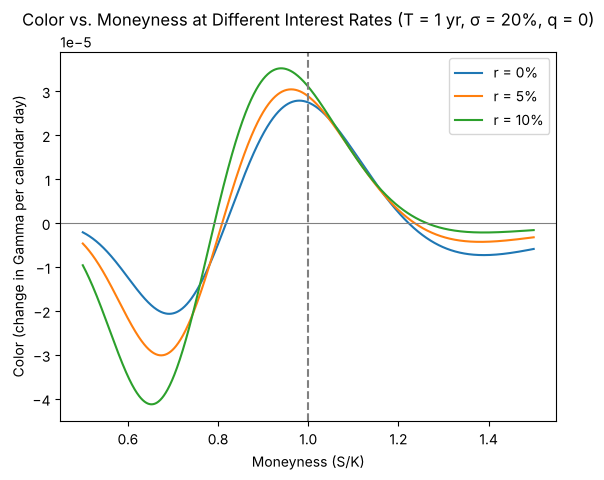

In [12]:
for rate in RATES:
    c = color(S_GRID, K, T_BASE, rate, Q_BASE, SIGMA_BASE)
    plt.plot(moneyness, c, label=f"r = {rate:.0%}")
    print(f"r = {rate:.0%}: most negative {c.min():.8f} at S/K = {moneyness[np.argmin(c)]:.3f}, "
          f"most positive {c.max():.8f} at S/K = {moneyness[np.argmax(c)]:.3f}, "
          f"changes sign at S/K = {', '.join(f'{x:.3f}' for x in sign_changes(moneyness, c))}, "
          f"ATM {color(K, K, T_BASE, rate, Q_BASE, SIGMA_BASE):.8f}")

plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("Moneyness (S/K)")
plt.ylabel("Color (change in Gamma per calendar day)")
plt.title("Color vs. Moneyness at Different Interest Rates (T = 1 yr, σ = 20%, q = 0)")
plt.legend()
plt.show()

### Observations

1. **$r = 0\%$ shows Color without drift:** the peak is +0.00002788 at $S/K \approx 0.980$, almost at the strike, and the trough is −0.00002064 at 0.692. ATM Color is +0.00002746.

2. **Higher rates stretch both sides rather than shifting the curve:** the trough deepens from −0.00002064 at 0% to −0.00003009 at 5% and −0.00004123 at 10%, while the peak rises from +0.00002788 to +0.00003044 and +0.00003523. This is different from Charm, where higher rates pushed the whole curve down. The drift part of Color has the sign of $d_1$: it deepens the OTM wing (where $d_1 < 0$) and adds to the area near the money (where $d_1 > 0$).

3. **The curve moves left and the positive band widens slightly:** the peak moves from $S/K \approx 0.980$ to 0.962 and 0.940, and the sign changes move from 0.818 and 1.223 to 0.810 and 1.237, then 0.792 and 1.263. These match, to within the grid spacing, the extremes of Charm at the same rates in notebook 02. ATM Color rises gently: +0.00002746, +0.00002885 and +0.00003104.

4. **The rate effect fades far from the strike:** every part of Color is weighted by Gamma, which is small far from the strike, so the three curves come together near zero at both edges.

## Color vs Moneyness at Different Dividend Yields

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for three dividend yields: $q = 0\%$, $5\%$ and $10\%$
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$
- **Shows:** a single curve per dividend yield. Unlike Charm, call and put Color stay identical when $q > 0$, so no separate put panel is needed.

The printed lines also check that call and put Color are the same at every stock price: the one-day change in Gamma is computed separately from call Delta and from put Delta, and the largest gap between them is printed.

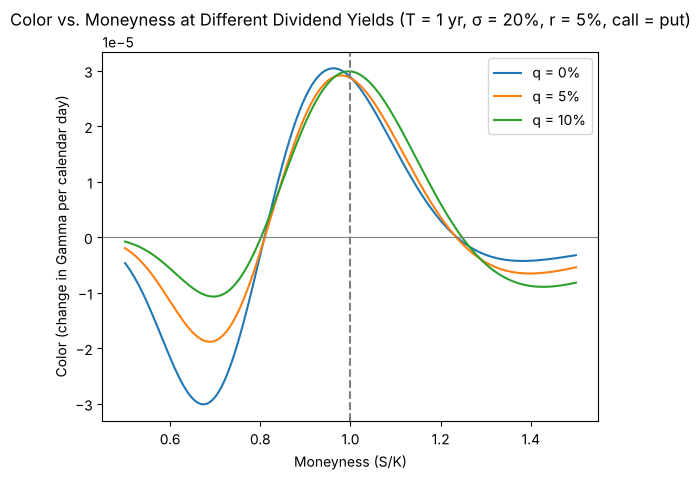

q = 0%: most negative -0.00003009 at S/K = 0.674, most positive 0.00003044 at S/K = 0.962, changes sign at S/K = 0.810, 1.237, lowest ITM value -0.00000426 at S/K = 1.382
        dividend part up to 0.00000000; call minus put one-day change in Gamma: largest gap 1.1e-14
q = 5%: most negative -0.00001883 at S/K = 0.688, most positive 0.00002917 at S/K = 0.979, changes sign at S/K = 0.811, 1.235, lowest ITM value -0.00000652 at S/K = 1.398
        dividend part up to 0.00000271; call minus put one-day change in Gamma: largest gap 1.4e-14
q = 10%: most negative -0.00001068 at S/K = 0.696, most positive 0.00002990 at S/K = 0.996, changes sign at S/K = 0.802, 1.248, lowest ITM value -0.00000893 at S/K = 1.428
        dividend part up to 0.00000490; call minus put one-day change in Gamma: largest gap 1.5e-14


In [13]:
for q in DIV_YIELDS:
    c = color(S_GRID, K, T_BASE, R_BASE, q, SIGMA_BASE)
    plt.plot(moneyness, c, label=f"q = {q:.0%}")

plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("Moneyness (S/K)")
plt.ylabel("Color (change in Gamma per calendar day)")
plt.title("Color vs. Moneyness at Different Dividend Yields (T = 1 yr, σ = 20%, r = 5%, call = put)")
plt.legend()
plt.show()

for q in DIV_YIELDS:
    c = color(S_GRID, K, T_BASE, R_BASE, q, SIGMA_BASE)
    _, _, _, div_part = color_parts(S_GRID, K, T_BASE, R_BASE, q, SIGMA_BASE)
    call_change = (gamma_from_delta(S_GRID, K, T_BASE - one_day, R_BASE, q, SIGMA_BASE, "call")
                   - gamma_from_delta(S_GRID, K, T_BASE, R_BASE, q, SIGMA_BASE, "call"))
    put_change = (gamma_from_delta(S_GRID, K, T_BASE - one_day, R_BASE, q, SIGMA_BASE, "put")
                  - gamma_from_delta(S_GRID, K, T_BASE, R_BASE, q, SIGMA_BASE, "put"))
    print(f"q = {q:.0%}: most negative {c.min():.8f} at S/K = {moneyness[np.argmin(c)]:.3f}, "
          f"most positive {c.max():.8f} at S/K = {moneyness[np.argmax(c)]:.3f}, "
          f"changes sign at S/K = {', '.join(f'{x:.3f}' for x in sign_changes(moneyness, c))}, "
          f"lowest ITM value {c[moneyness > 1.2].min():.8f} at S/K = {moneyness[moneyness > 1.2][np.argmin(c[moneyness > 1.2])]:.3f}")
    print(f"        dividend part up to {div_part.max():.8f}; "
          f"call minus put one-day change in Gamma: largest gap {np.abs(call_change - put_change).max():.1e}")

### Observations

1. **Calls and puts stay identical:** the largest gap between the one-day change in call Gamma and put Gamma is of order $10^{-14}$, which is floating-point rounding. In notebook 02, dividends separated call and put Charm by $\frac{qe^{-qT}}{365}$, but that gap was the same at every stock price, so it disappears when we take the slope with respect to $S$.

2. **Dividends shrink the OTM trough:** the most negative Color goes from −0.00003009 at $q = 0\%$ to −0.00001883 at 5% and −0.00001068 at 10%, moving slightly toward the money (0.674, 0.688, 0.696). With $q = r = 5\%$ the drift part is zero, and at $q = 10\%$ it reverses: the stock is now expected to shrink, so the Gamma peak moves from $S/K \approx 0.896$ almost to the strike ($e^{-0.01} \approx 0.990$), and there is less OTM Gamma to lose.

3. **The peak hardly changes size but moves to the strike:** +0.00003044, +0.00002917 and +0.00002990, at $S/K \approx 0.962$, 0.979 and 0.996. The sign changes barely move (0.810/1.237, 0.811/1.235, 0.802/1.248). The dividend part itself is small, at most +0.00000271 at 5% and +0.00000490 at 10%.

4. **The ITM wing behaves the opposite way:** its lowest value deepens from −0.00000426 at $S/K \approx 1.382$ to −0.00000652 and −0.00000893. A dividend-paying stock is expected to drift down toward the strike, which keeps OTM call Gamma alive longer but drains ITM call Gamma a little faster. The same applies to puts, with OTM and ITM swapped.

## Summary

All Color values are per calendar day, i.e. the change in Gamma over one day, for $K = 100$. Unless stated otherwise: $T = 1$ year, $\sigma = 20\%$, $r = 5\%$, $q = 0$.

### What Color measures, and its link to Gamma, Charm and Theta

- Color is the daily drift in Gamma when the stock price does not move. In the base-case table, it matches the actual one-day change in Gamma to three significant figures, with a gap of about $3 \times 10^{-8}$.
- As expiry approaches, the Gamma curve sharpens into a spike at the strike, and Color measures how fast each option's Gamma grows toward that spike or drains away from it.
- Color is also the slope of the Charm curve: the numerical slope of Charm matches the formula, and Color is zero exactly where Charm reaches its extremes ($S/K \approx 0.810$ and $1.237$ in the base case). It is therefore also the curvature of Theta.

### Where Color reaches its extremes

- In the base case, Color is most positive at $S/K \approx 0.962$ (+0.00003044), most negative at $S/K \approx 0.674$ (−0.00003009), and changes sign at $S/K \approx 0.810$ and $1.237$.
- As expiry approaches, the extremes grow very sharply and move toward the strike: +0.0103 and −0.0052 per day at 1 week, at $S/K \approx 0.999$ and 0.952.

### Sign, and calls vs puts

- Color is positive inside a band around the strike (Gamma rises as time passes) and negative outside it (Gamma drains away). The band narrows as expiry approaches.
- Call and put Color are identical at every dividend yield, because call and put Gamma are identical. This is the main difference from Charm.

### Across moneyness

- **Near the money:** Gamma builds up as time passes, so Color is positive and largest just below the strike.
- **Moderately OTM calls (ITM puts):** Gamma drains away fastest here, so Color is most negative.
- **Moderately ITM calls (OTM puts):** Gamma also drains away, but more gently when $r > q$.
- **Far from the strike:** Gamma is already close to zero, so Color fades toward zero.

### Effect of each parameter

- **Time to maturity:** Color grows very sharply as expiry approaches (by a factor of about 340 from 1 year to 1 week) and becomes concentrated in a narrow band around the strike. ATM Color grows like $T^{-3/2}$ (+0.0000288 at 1 year to +0.1906 at 1 day).
- **Volatility:** lower volatility makes Color taller and narrower; higher volatility flattens it, spreads it out and moves its peak further below the strike.
- **Risk-free rate:** higher $r$ deepens the OTM trough and raises the peak, moving both left; unlike Charm, it does not push the whole curve one way.
- **Dividend yield:** higher $q$ shrinks the OTM trough, moves the peak to the strike and slightly deepens the ITM wing, with calls and puts still identical.

### Turning points and nonlinearities

- Color changes sign twice across moneyness, at the extremes of Charm; the sign-change points move toward ATM as expiry approaches.
- Against time to maturity, OTM and ITM Color change sign: negative below about 99 and 81 days, positive above. They are strongest at about 19 and 15 days. ATM Color is strongest at the shortest maturity and never changes sign.

### Comparison with class material

- **Matches the Delta reference notebook:** its Delta-vs-moneyness plot at different maturities shows the Delta curve steepening around the strike as maturity shortens. The steepness of that curve is Gamma, so the steepening is Gamma rising at the money and falling away from it. Color measures how fast that happens.
- **Extends it:** the speed is not uniform. It depends on moneyness, explodes at the money near expiry, changes sign twice across strikes, and its shape is set by a balance between the distribution narrowing, Delta settling at 0 or 1, the loss of expected growth, and dividends.